In [13]:
import json
import random
import time
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.model_selection import train_test_split
from tqdm import tqdm

In [14]:
torch.manual_seed(0)
random.seed(0)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Using device:", device)

Using device: cuda


In [15]:
images_path = Path("dataset/images")
data = json.loads(Path("dataset/gt_public.json").read_text())

image_ids = list(data.keys())
train_ids, rest_ids = train_test_split(image_ids, test_size=0.2, random_state=0)
val_ids, test_ids = train_test_split(rest_ids, test_size=0.5, random_state=0)

print(f"Train: {len(train_ids)}, Val: {len(val_ids)}, Test: {len(test_ids)}")

Train: 41470, Val: 5184, Test: 5184


In [16]:
class CraterDetectionDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, i):
        image_id = self.image_ids[i]

        image = Image.open(images_path / f"{image_id}.png").convert("RGB")
        image = torch.tensor(np.array(image), dtype=torch.float32).permute(2, 0, 1) / 255.0

        boxes = [[x, y, x + w, y + h] for x, y, w, h in data[image_id] if w > 0 and h > 0]
        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.ones(len(boxes), dtype=torch.int64)

        return image, {"boxes": boxes, "labels": labels}

8 torch.Size([3, 256, 256])
{'boxes': tensor([[ 74., 135., 135., 196.],
        [179., 126., 190., 137.],
        [ 14.,  94.,  31., 110.]]), 'labels': tensor([1, 1, 1])}


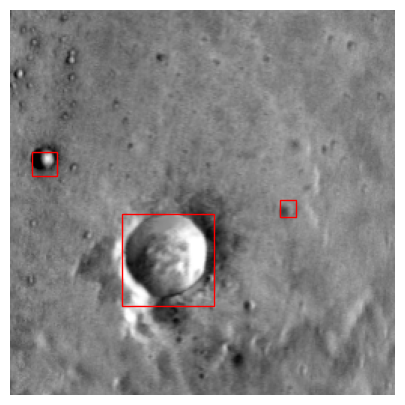

In [17]:
def collate_fn(batch):
    return tuple(zip(*batch))


train_set = CraterDetectionDataset(train_ids)
val_set = CraterDetectionDataset(val_ids)
test_set = CraterDetectionDataset(test_ids)

train_loader = DataLoader(train_set, batch_size=8, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_set, batch_size=8, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_set, batch_size=8, shuffle=False, collate_fn=collate_fn)

images, targets = next(iter(train_loader))
print(len(images), images[0].shape)
print(targets[0])

# check that the converted boxes still sit on the craters
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(images[0].permute(1, 2, 0))
for x1, y1, x2, y2 in targets[0]["boxes"]:
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=1))
ax.axis("off")
plt.show()

In [18]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

model = fasterrcnn_resnet50_fpn(weights="DEFAULT", min_size=256)

in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)

model.to(device)
print(sum(p.numel() for p in model.parameters()))

41299161


In [19]:
images, targets = next(iter(train_loader))
images = [img.to(device) for img in images]
targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

# training mode: you give it images AND boxes, it gives back losses
model.train()
loss_dict = model(images, targets)
print(loss_dict)

# eval mode: you give it only images, it gives back boxes
model.eval()
with torch.no_grad():
    outputs = model(images)
print(outputs[0]["boxes"][:3])
print(outputs[0]["scores"][:3])

{'loss_classifier': tensor(0.7026, device='cuda:0', grad_fn=<NllLossBackward0>), 'loss_box_reg': tensor(0.2103, device='cuda:0', grad_fn=<DivBackward0>), 'loss_objectness': tensor(4.5487, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>), 'loss_rpn_box_reg': tensor(0.3717, device='cuda:0', grad_fn=<DivBackward0>)}
tensor([[ 58.9629, 134.7383,  73.7728, 146.4440],
        [ 83.4601, 125.5106, 100.4863, 137.7051],
        [ 71.6434, 131.0047,  87.4417, 145.2398]], device='cuda:0')
tensor([0.7031, 0.6917, 0.6910], device='cuda:0')


In [20]:
from torchvision.ops import box_iou

cutoffs = [0.3, 0.5, 0.7, 0.8, 0.9]

def count_matches(pred_boxes, true_boxes, iou_threshold=0.5):
    if len(pred_boxes) == 0 or len(true_boxes) == 0:
        return 0

    ious = box_iou(pred_boxes, true_boxes)
    matches = 0
    for i in range(len(pred_boxes)):
        j = ious[i].argmax()
        if ious[i, j] >= iou_threshold:
            matches += 1
            ious[:, j] = -1  # this real crater is taken
    return matches


def evaluate(model, loader):
    model.eval()
    tp = {c: 0 for c in cutoffs}
    n_pred = {c: 0 for c in cutoffs}
    n_true = 0

    with torch.no_grad():
        for images, targets in loader:
            images = [img.to(device) for img in images]
            outputs = model(images)

            for out, target in zip(outputs, targets):
                true_boxes = target["boxes"].to(device)
                n_true += len(true_boxes)

                for c in cutoffs:
                    pred_boxes = out["boxes"][out["scores"] > c]
                    n_pred[c] += len(pred_boxes)
                    tp[c] += count_matches(pred_boxes, true_boxes)

    results = {}
    for c in cutoffs:
        precision = tp[c] / n_pred[c] if n_pred[c] > 0 else 0.0
        recall = tp[c] / n_true
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
        results[c] = {"precision": precision, "recall": recall, "f1": f1}

    best_cutoff = max(results, key=lambda c: results[c]["f1"])
    return results[best_cutoff], best_cutoff

In [21]:
run_name = "01-baseline"
run_dir = Path("src/faster-rcnn") / run_name
run_dir.mkdir(parents=True, exist_ok=True)

optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9, weight_decay=0.0005)

epochs = 10
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

In [22]:
print(len(train_loader.dataset), len(val_loader.dataset))

41470 5184


In [23]:
history = {"train_loss": [], "val_precision": [], "val_recall": [], "val_f1": [], "best_cutoff": [], "lr": []}
best_f1 = 0.0

for epoch in range(epochs):
    model.train()
    running_loss, n = 0.0, 0
    start = time.time()

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}", mininterval=1.0)
    for images, targets in progress:
        ## cant you do this once outside the loop as a preprocessing step?
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(images)
        n += len(images)
        progress.set_postfix(loss=f"{running_loss / n:.4f}")

    train_loss = running_loss / n
    val, cutoff = evaluate(model, val_loader)
    lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_precision"].append(val["precision"])
    history["val_recall"].append(val["recall"])
    history["val_f1"].append(val["f1"])
    history["best_cutoff"].append(cutoff)
    history["lr"].append(lr)
    (run_dir / "history.json").write_text(json.dumps(history))

    saved = ""
    if val["f1"] > best_f1:
        best_f1 = val["f1"]
        torch.save(model.state_dict(), run_dir / "model.pt")
        saved = " (saved)"

    print(f"Epoch {epoch + 1}: train loss {train_loss:.4f} | val precision {val['precision']:.3f}, "
          f"recall {val['recall']:.3f}, F1 {val['f1']:.3f} at cutoff {cutoff} | lr {lr:.6f} | "
          f"{time.time() - start:.0f}s{saved}")

Epoch 1/10: 100%|██████████| 5184/5184 [06:35<00:00, 13.12it/s, loss=0.2815]


Epoch 1: train loss 0.2815 | val precision 0.836, recall 0.732, F1 0.781 at cutoff 0.9 | lr 0.005000 | 440s (saved)


Epoch 2/10: 100%|██████████| 5184/5184 [06:40<00:00, 12.94it/s, loss=0.2421]


Epoch 2: train loss 0.2421 | val precision 0.773, recall 0.796, F1 0.784 at cutoff 0.8 | lr 0.004878 | 445s (saved)


Epoch 3/10: 100%|██████████| 5184/5184 [06:32<00:00, 13.20it/s, loss=0.2319]


...

Epoch 8: train loss 0.2022 | val precision 0.787, recall 0.798, F1 0.792 at cutoff 0.8 | lr 0.001031 | 436s


Epoch 9/10: 100%|██████████| 5184/5184 [06:31<00:00, 13.24it/s, loss=0.1976]


Epoch 9: train loss 0.1976 | val precision 0.778, recall 0.809, F1 0.793 at cutoff 0.8 | lr 0.000477 | 436s


Epoch 10/10: 100%|██████████| 5184/5184 [06:32<00:00, 13.21it/s, loss=0.1940]


Epoch 10: train loss 0.1940 | val precision 0.789, recall 0.802, F1 0.796 at cutoff 0.8 | lr 0.000122 | 437s (saved)


model: Faster R-CNN, ResNet-50 + FPN, pretrained on COCO, new 2-class head
image size: min_size=256 (no enlarging)
parameters: 41,299,161
optimizer: SGD, lr=0.005, momentum=0.9, weight_decay=0.0005, cosine schedule
batch size: 8
epochs: 10
cutoffs tried: [0.3, 0.5, 0.7, 0.8, 0.9]
match rule: box IoU >= 0.5
best epoch: 10
best val F1: 0.7958 at cutoff 0.8
precision: 0.7895
recall: 0.8021



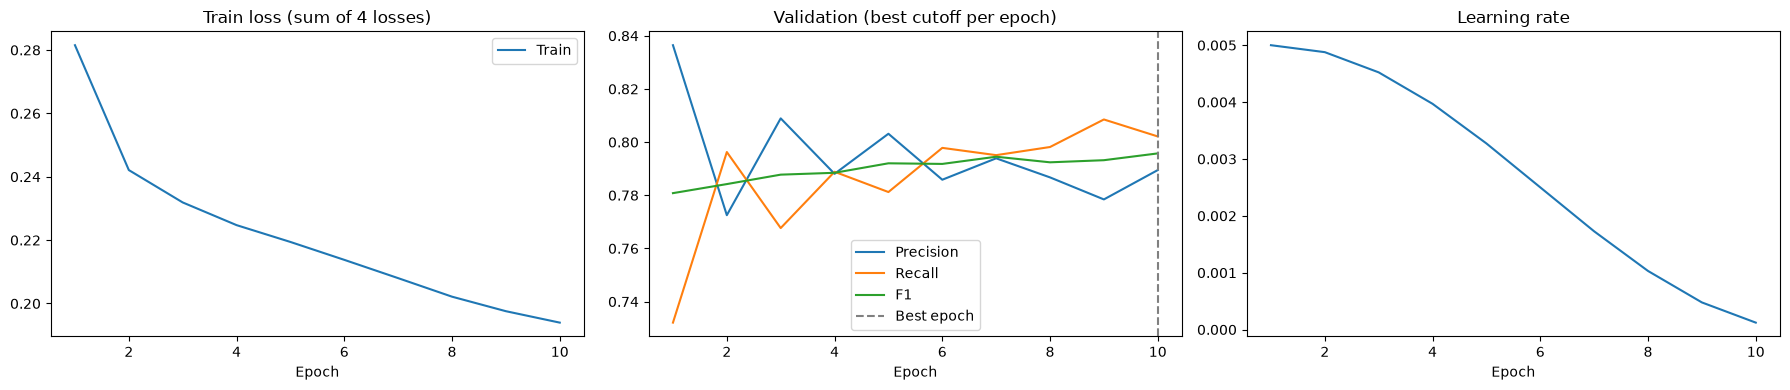

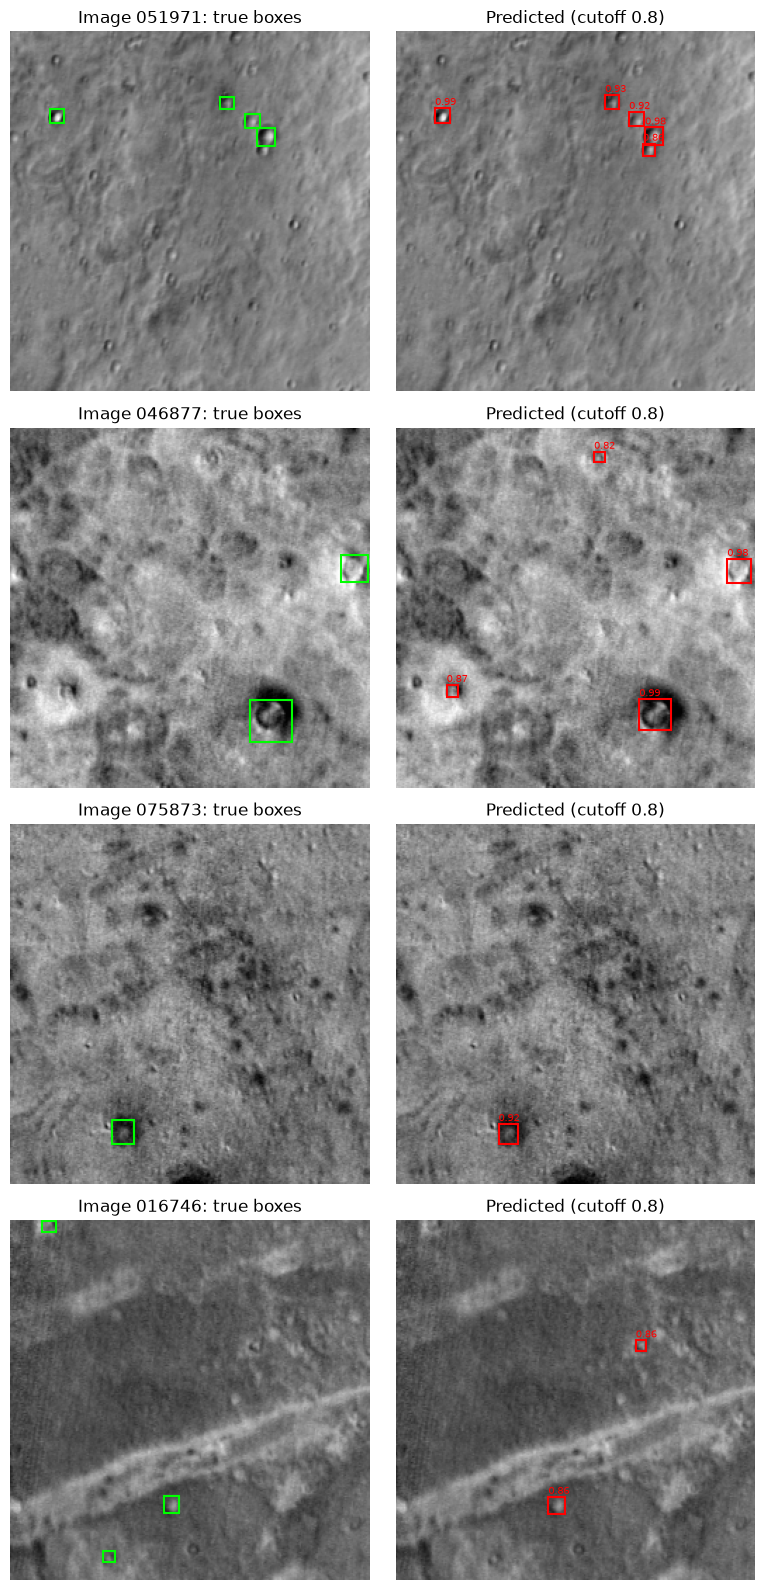

In [24]:
# 0. Load the saved history
history = json.loads((run_dir / "history.json").read_text())

# 1. Notes
best_epoch = history["val_f1"].index(max(history["val_f1"]))
best_cutoff = history["best_cutoff"][best_epoch]
n_params = sum(p.numel() for p in model.parameters())

notes = f"""model: Faster R-CNN, ResNet-50 + FPN, pretrained on COCO, new 2-class head
image size: min_size=256 (no enlarging)
parameters: {n_params:,}
optimizer: SGD, lr=0.005, momentum=0.9, weight_decay=0.0005, cosine schedule
batch size: 8
epochs: {len(history["val_f1"])}
cutoffs tried: {cutoffs}
match rule: box IoU >= 0.5
best epoch: {best_epoch + 1}
best val F1: {history["val_f1"][best_epoch]:.4f} at cutoff {best_cutoff}
precision: {history["val_precision"][best_epoch]:.4f}
recall: {history["val_recall"][best_epoch]:.4f}
"""
(run_dir / "notes.txt").write_text(notes)
print(notes)

# 2. Curves: train loss, val precision / recall / F1, learning rate
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4))

ax1.plot(epochs_range, history["train_loss"], label="Train")
ax1.set_title("Train loss (sum of 4 losses)")
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(epochs_range, history["val_precision"], label="Precision")
ax2.plot(epochs_range, history["val_recall"], label="Recall")
ax2.plot(epochs_range, history["val_f1"], label="F1")
ax2.axvline(best_epoch + 1, linestyle="--", color="gray", label="Best epoch")
ax2.set_title("Validation (best cutoff per epoch)")
ax2.set_xlabel("Epoch")
ax2.legend()

ax3.plot(epochs_range, history["lr"])
ax3.set_title("Learning rate")
ax3.set_xlabel("Epoch")

plt.tight_layout()
plt.savefig(run_dir / "curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Example predictions from the best saved model
model.load_state_dict(torch.load(run_dir / "model.pt", map_location=device))
model.eval()

fig, axes = plt.subplots(4, 2, figsize=(8, 16))

for i, (ax_true, ax_pred) in enumerate(axes):
    image, target = val_set[i]
    with torch.no_grad():
        out = model([image.to(device)])[0]
    keep = out["scores"] > best_cutoff
    pred_boxes = out["boxes"][keep].cpu()
    pred_scores = out["scores"][keep].cpu()

    ax_true.imshow(image.permute(1, 2, 0))
    for x1, y1, x2, y2 in target["boxes"]:
        ax_true.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=1.5))
    ax_true.set_title(f"Image {val_ids[i]}: true boxes")

    ax_pred.imshow(image.permute(1, 2, 0))
    for (x1, y1, x2, y2), s in zip(pred_boxes, pred_scores):
        ax_pred.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=1.5))
        ax_pred.text(x1, y1 - 2, f"{s:.2f}", color="red", fontsize=7)
    ax_pred.set_title(f"Predicted (cutoff {best_cutoff})")

    for ax in (ax_true, ax_pred):
        ax.axis("off")

plt.tight_layout()
plt.savefig(run_dir / "predictions.png", dpi=150, bbox_inches="tight")
plt.show()